In [ ]:
pip install pandas matplotlib wordcloud

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

In [19]:
# Step 1: Load the dataset
file_path = "Excercise4_Input_flipkart_product.csv"

df = pd.read_csv(
    file_path,
    encoding="latin1",
    encoding_errors="replace"
)

# Clean column names
df.columns = df.columns.str.strip()

# Rename ProductName to Product Name
df.rename(columns={'ProductName': 'Product Name'}, inplace=True)

# Display first five records
print("First five records:")
print(df.head())

# Display column names
print("\nColumn names:")
print(df.columns.tolist())


First five records:
                                        Product Name     Price Rate  \
0  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  ??3,999    5   
1  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  ??3,999    5   
2  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  ??3,999    3   
3  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  ??3,999    1   
4  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  ??3,999    3   

            Review                                            Summary  
0           Super!  Great cooler.. excellent air flow and for this...  
1          Awesome             Best budget 2 fit cooler. Nice cooling  
2             Fair  The quality is good but the power of air is de...  
3  Useless product                 Very bad product it's a only a fan  
4             Fair                                      Ok ok product  

Column names:
['Product Name', 'Price', 'Rate', 'Review', 'Summary']


In [20]:
# Step 2: Clean the Price and Rate columns

# Remove currency symbols, commas and other unwanted characters
df['Price'] = (
    df['Price'].astype(str)
    .str.replace(r'[^\d.]', '', regex=True)
)

df['Rate'] = (
    df['Rate'].astype(str)
    .str.replace(r'[^\d.]', '', regex=True)
)

# Convert columns into numeric values
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')

# Remove records with missing or invalid values
df = df.dropna(subset=['Product Name', 'Price', 'Rate'])

# Display first five records
print("First five records:")
print(df.head())

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

First five records:
                                        Product Name   Price  Rate  \
0  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  3999.0   5.0   
1  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  3999.0   5.0   
2  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  3999.0   3.0   
3  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  3999.0   1.0   
4  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  3999.0   3.0   

            Review                                            Summary  
0           Super!  Great cooler.. excellent air flow and for this...  
1          Awesome             Best budget 2 fit cooler. Nice cooling  
2             Fair  The quality is good but the power of air is de...  
3  Useless product                 Very bad product it's a only a fan  
4             Fair                                      Ok ok product  

Column names:
['Product Name', 'Price', 'Rate', 'Review', 'Summary']


In [21]:
# Step 3: Group by Product Name and calculate mean rating and price
items = df.groupby('Product Name').agg(
    Mean_Rating=('Rate', 'mean'),
    Mean_Price=('Price', 'mean')
).reset_index()

# Round the results to two decimal places
items['Mean_Rating'] = items['Mean_Rating'].round(2)
items['Mean_Price'] = items['Mean_Price'].round(2)

# Display the summary DataFrame
print("\nProduct-wise Average Rating and Price:")
print(items)


Product-wise Average Rating and Price:
                                          Product Name  Mean_Rating  \
0    1170-BL-BR Unique New Day & Date Analog Watch ...         3.99   
1        38024PP25 Minimalists Analog Watch  - For Men         4.89   
2    3D METRO SUPER STORE JUICER_Gduumy 1 Juicer,1 ...         3.67   
3    3D METRO SUPER STORE METRO_MIXER Pro 0 Juicer ...         4.75   
4               77085PP03 Volt Analog Watch  - For Men         4.71   
..                                                 ...          ...   
806  the indian casa Cricket Net 10x20 Feet Nylon C...         3.92   
807  thos 5 Layer Simple Bookshelf/Multipurpose Rac...         3.38   
808  thos 5 Layer Simple Bookshelf/Multipurpose Rac...         3.41   
809  vesco Kiddo 14" Cycle for Kids Bicycles age 3 ...         4.23   
810  wood city handicrafts wooden round side coffee...         3.83   

     Mean_Price  
0         299.0  
1         850.0  
2         417.0  
3         199.0  
4         699.0  

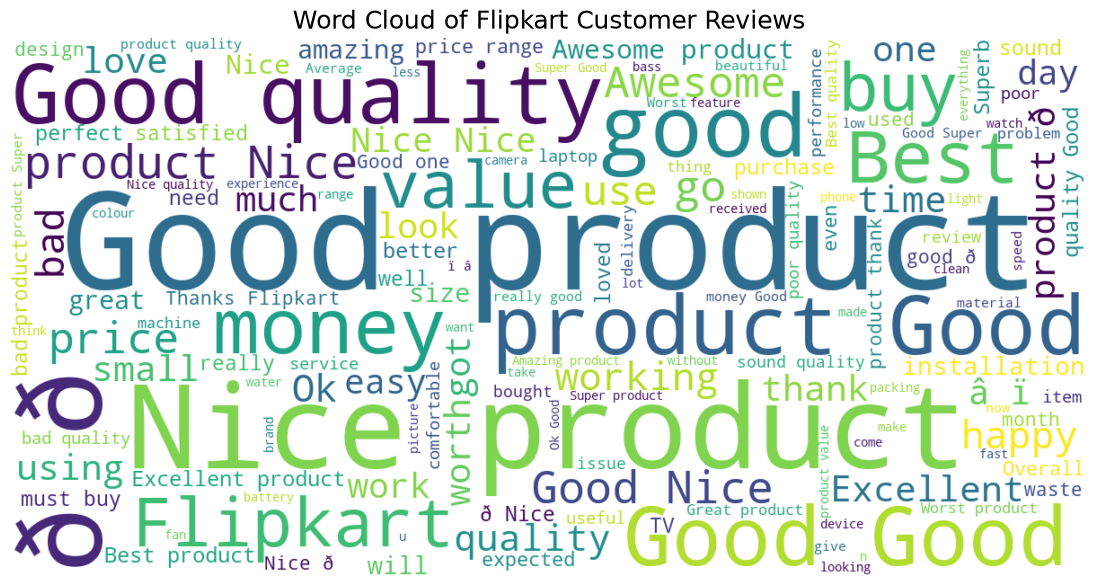

In [22]:
# Step 4: Generate Word Cloud using Summary column

# Combine all customer feedback summaries into one text
text = ' '.join(df['Summary'].dropna().astype(str))

# Define stopwords
stopwords = set(STOPWORDS)

# Generate Word Cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    stopwords=stopwords,
    max_words=150,
    colormap='viridis'
).generate(text)

# Display Word Cloud
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Flipkart Customer Reviews',
          fontsize=18)
plt.show()

In [23]:
# Step 5: Save the product summary as a CSV file
items.to_csv('Excercise4_Output_product_summary.csv', index=False)

print("\nProduct summary saved as Excercise4_Output_product_summary.csv")


Product summary saved as Excercise4_Output_product_summary.csv
